# 05 - Avaliacao Clinica (conjunto de teste)
Camada de decisao clinica. 
---
Este notebook trabalha com artefactos commited, sendo que os outputs são discutidos seccção a secção.


In [2]:
# Importacoes 
import os, sys
import numpy as np
import pandas as pd

from pathlib import Path



In [3]:
# Google colab check: Bootstrap - deteta Colab vs local, monta o Drive se necessario e coloca o repo
# no sys.path. 
try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_ROOT = Path('/content/drive/MyDrive/ophthalmic-referral-cnn')
except ImportError:
    REPO_ROOT = Path.cwd()
    while not (REPO_ROOT / 'src').is_dir():
        if REPO_ROOT.parent == REPO_ROOT:
            raise RuntimeError("Repo root not found — no 'src' directory above cwd")
        REPO_ROOT = REPO_ROOT.parent

sys.path.insert(0, str(REPO_ROOT))

from src import bootstrap, data, viz

IN_COLAB = bootstrap.setup()
REPO_DIR = bootstrap.get_repo_dir(IN_COLAB)
DATA_DIR = REPO_ROOT
print("DATA_DIR:", DATA_DIR)
print("contents:", os.listdir(DATA_DIR))
base_dir = str(DATA_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR: /content/drive/MyDrive/ophthalmic-referral-cnn
contents: ['Deep_Learning_Base.ipynb', 'notebooks', 'src', 'ocular', 'artifacts']


In [4]:
# Diretorios de artefactos -- sempre em Drive (derivam de REPO_DIR).
ARTIFACT_DIRS = bootstrap.get_artifact_dirs(REPO_DIR)
ARTIFACTS_DIR = ARTIFACT_DIRS["artifacts"]
MODELS_DIR    = ARTIFACT_DIRS["models"]
PREDS_DIR     = ARTIFACT_DIRS["preds"]
HISTORY_DIR   = ARTIFACT_DIRS["history"]
for _d in (MODELS_DIR, PREDS_DIR, HISTORY_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print("Artefactos em:", ARTIFACTS_DIR)

Artefactos em: /content/drive/MyDrive/ophthalmic-referral-cnn/artifacts


In [5]:
# Registo de previsoes reconstruido a partir de artefactos committed: a tabela de
# resultados da a lista de modelos; para cada um carrega-se a matriz de
# probabilidades de teste (preds/{slug}_proba.npy). Nenhuma imagem, nenhum modelo.
df_results = pd.read_csv(ARTIFACTS_DIR / "results.csv")
y_test = np.load(PREDS_DIR / "y_test.npy")
class_names = data.CLASS_NAMES

probas = {}
for nome in df_results["Modelo"]:
    probas[nome] = np.load(PREDS_DIR / f"{data.slug(nome)}_proba.npy")

print("Modelos:", list(probas))
print("y_test:", y_test.shape)


Modelos: ['Baseline (sem class weight)', 'Baseline (class weight)', 'Regularizado', 'ResNet50 (feature extraction)', 'ResNet50 (fine-tuned)', 'Multimodal (ResNet50 + BERTimbau)', 'EfficientNetB0 (feature extraction)', 'EfficientNetB0 (fine-tuned)', 'Text-only (TF-IDF + Regressão Logística)']
y_test: (507,)


## 5.1 Matriz de confusão e classification report
A matriz de confusão permite analisar em detalhe os erros do modelo por classe,
distinguindo entre **Falsos Positivos** (FP) e **Falsos Negativos** (FN).

No contexto do **Use Case 3 — Sistema de Referenciação Hospitalar**, os erros não
têm o mesmo custo clínico:

- **Falso Negativo** (doente com patologia classificado como Normal) — o caso mais
  grave: o doente não é encaminhado e a patologia fica por diagnosticar.
- **Falso Positivo** (exame normal enviado para especialista) — indesejável mas
  menos grave: gera carga desnecessária no sistema, mas sem consequências para o doente.


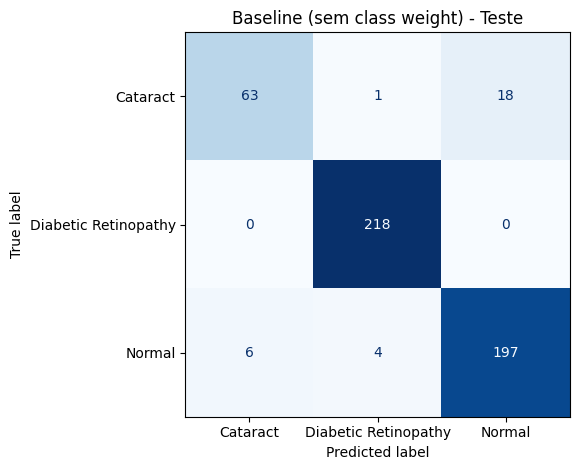

=== Baseline (sem class weight) | TESTE ===
                      precision    recall  f1-score   support

            Cataract       0.91      0.77      0.83        82
Diabetic Retinopathy       0.98      1.00      0.99       218
              Normal       0.92      0.95      0.93       207

            accuracy                           0.94       507
           macro avg       0.94      0.91      0.92       507
        weighted avg       0.94      0.94      0.94       507




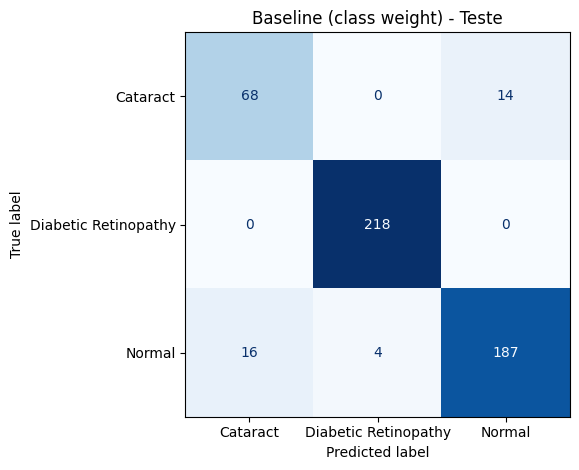

=== Baseline (class weight) | TESTE ===
                      precision    recall  f1-score   support

            Cataract       0.81      0.83      0.82        82
Diabetic Retinopathy       0.98      1.00      0.99       218
              Normal       0.93      0.90      0.92       207

            accuracy                           0.93       507
           macro avg       0.91      0.91      0.91       507
        weighted avg       0.93      0.93      0.93       507




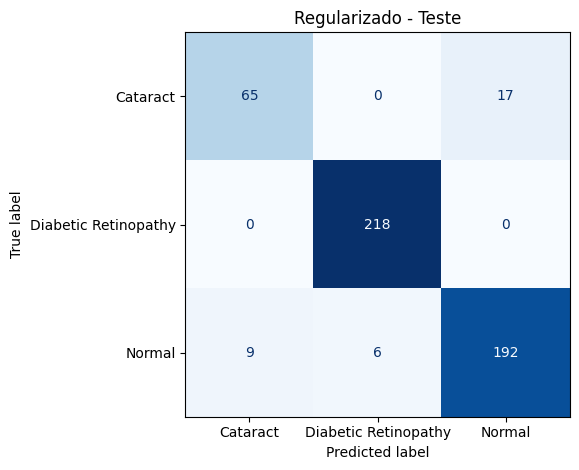

=== Regularizado | TESTE ===
                      precision    recall  f1-score   support

            Cataract       0.88      0.79      0.83        82
Diabetic Retinopathy       0.97      1.00      0.99       218
              Normal       0.92      0.93      0.92       207

            accuracy                           0.94       507
           macro avg       0.92      0.91      0.91       507
        weighted avg       0.94      0.94      0.94       507




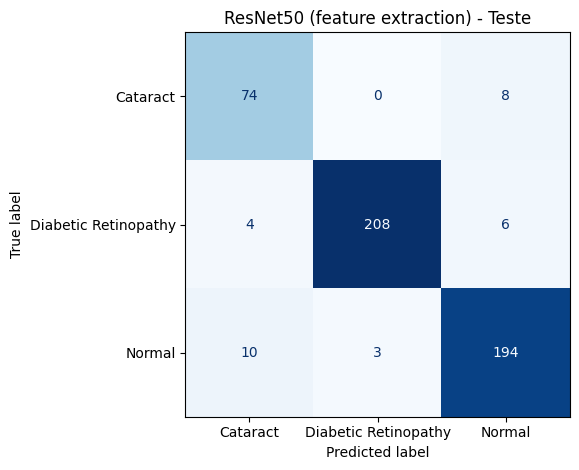

=== ResNet50 (feature extraction) | TESTE ===
                      precision    recall  f1-score   support

            Cataract       0.84      0.90      0.87        82
Diabetic Retinopathy       0.99      0.95      0.97       218
              Normal       0.93      0.94      0.93       207

            accuracy                           0.94       507
           macro avg       0.92      0.93      0.93       507
        weighted avg       0.94      0.94      0.94       507




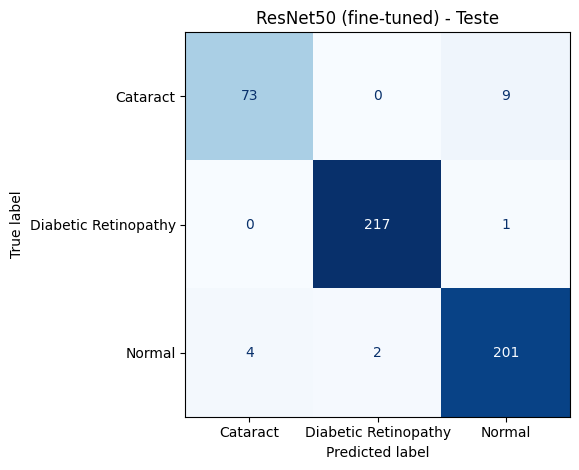

=== ResNet50 (fine-tuned) | TESTE ===
                      precision    recall  f1-score   support

            Cataract       0.95      0.89      0.92        82
Diabetic Retinopathy       0.99      1.00      0.99       218
              Normal       0.95      0.97      0.96       207

            accuracy                           0.97       507
           macro avg       0.96      0.95      0.96       507
        weighted avg       0.97      0.97      0.97       507




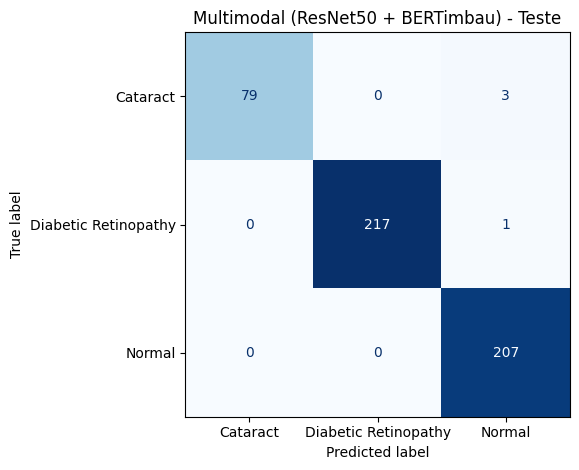

=== Multimodal (ResNet50 + BERTimbau) | TESTE ===
                      precision    recall  f1-score   support

            Cataract       1.00      0.96      0.98        82
Diabetic Retinopathy       1.00      1.00      1.00       218
              Normal       0.98      1.00      0.99       207

            accuracy                           0.99       507
           macro avg       0.99      0.99      0.99       507
        weighted avg       0.99      0.99      0.99       507




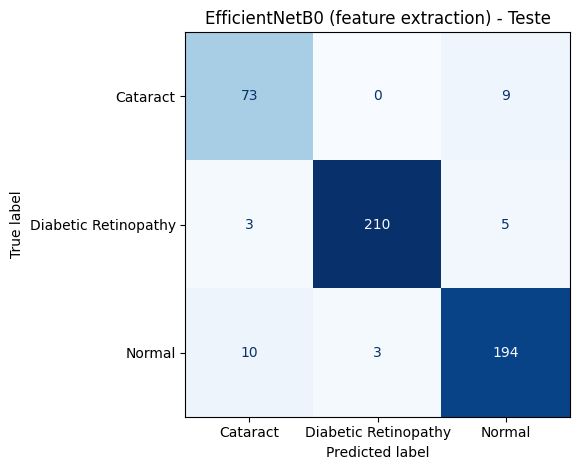

=== EfficientNetB0 (feature extraction) | TESTE ===
                      precision    recall  f1-score   support

            Cataract       0.85      0.89      0.87        82
Diabetic Retinopathy       0.99      0.96      0.97       218
              Normal       0.93      0.94      0.93       207

            accuracy                           0.94       507
           macro avg       0.92      0.93      0.93       507
        weighted avg       0.94      0.94      0.94       507




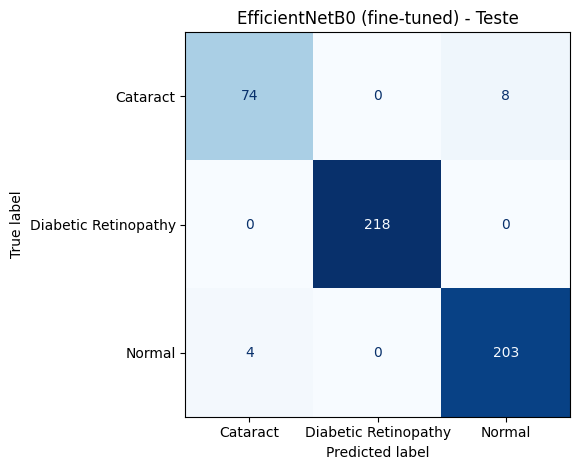

=== EfficientNetB0 (fine-tuned) | TESTE ===
                      precision    recall  f1-score   support

            Cataract       0.95      0.90      0.93        82
Diabetic Retinopathy       1.00      1.00      1.00       218
              Normal       0.96      0.98      0.97       207

            accuracy                           0.98       507
           macro avg       0.97      0.96      0.97       507
        weighted avg       0.98      0.98      0.98       507




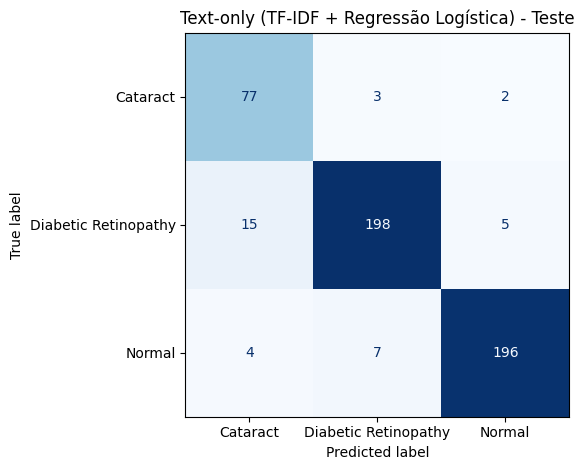

=== Text-only (TF-IDF + Regressão Logística) | TESTE ===
                      precision    recall  f1-score   support

            Cataract       0.80      0.94      0.87        82
Diabetic Retinopathy       0.95      0.91      0.93       218
              Normal       0.97      0.95      0.96       207

            accuracy                           0.93       507
           macro avg       0.91      0.93      0.92       507
        weighted avg       0.93      0.93      0.93       507



In [5]:
# Matriz de confusao + classification report no teste
for nome, proba in probas.items():
    print("\n" + "="*55)
    viz.plot_test_confusion(proba, y_test, class_names, nome_modelo=nome)


## 5.2 Curva ROC (Receiver Operating Characteristic) e Precision-Recall

A curva ROC representa a relação entre a **Sensibilidade** (Taxa de Verdadeiros Positivos)
e **1 - Especificidade** (Taxa de Falsos Positivos) para diferentes thresholds de decisão.
O valor de **AUC-ROC** (Área Sob a Curva) sintetiza o desempenho global do modelo —
um valor de 1.0 representa classificação perfeita e 0.5 equivale a uma decisão aleatória.


A curva Precision-Recall é particularmente relevante em datasets desbalanceados como
o nosso, onde a classe *cataract* representa a minoria. Ao contrário da curva ROC,
não é influenciada pelo elevado número de verdadeiros negativos, sendo uma avaliação
mais honesta do desempenho nas classes minoritárias.

O valor de **Average Precision (AP)** resume a curva — quanto mais próximo de 1.0,
melhor o modelo deteta a classe em questão independentemente do threshold escolhido.

No contexto clínico, um AUC-ROC elevado na classe *cataract* é crítico:
garante que o modelo consegue separar doentes com catarata de casos normais,
reduzindo o risco de falsos negativos no encaminhamento hospitalar.


ROC e Precision-Recall -- Baseline (sem class weight)


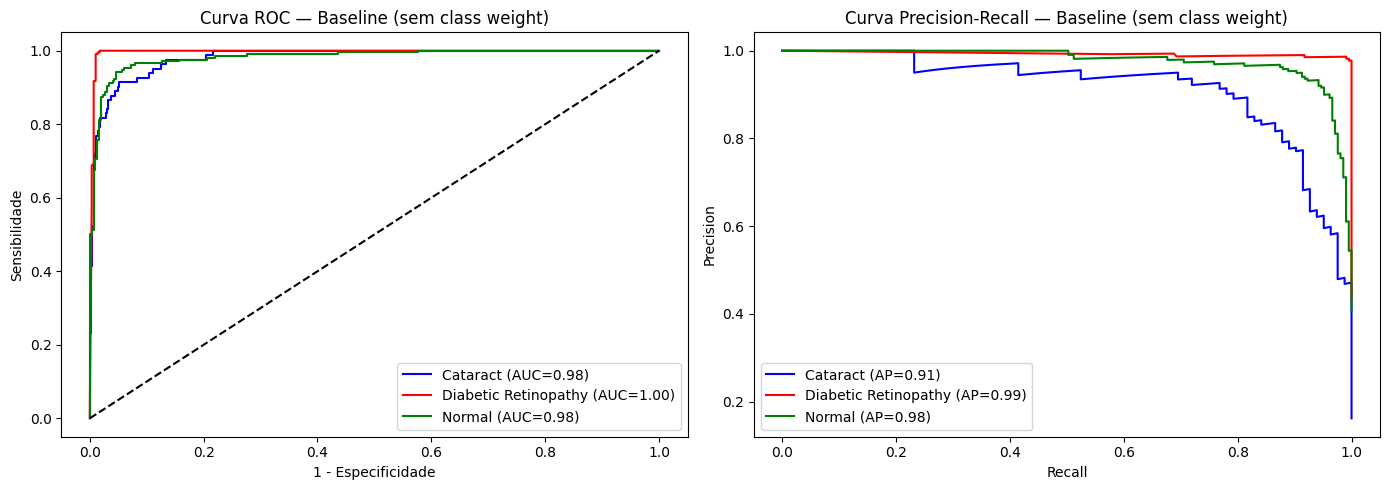


ROC e Precision-Recall -- Baseline (class weight)


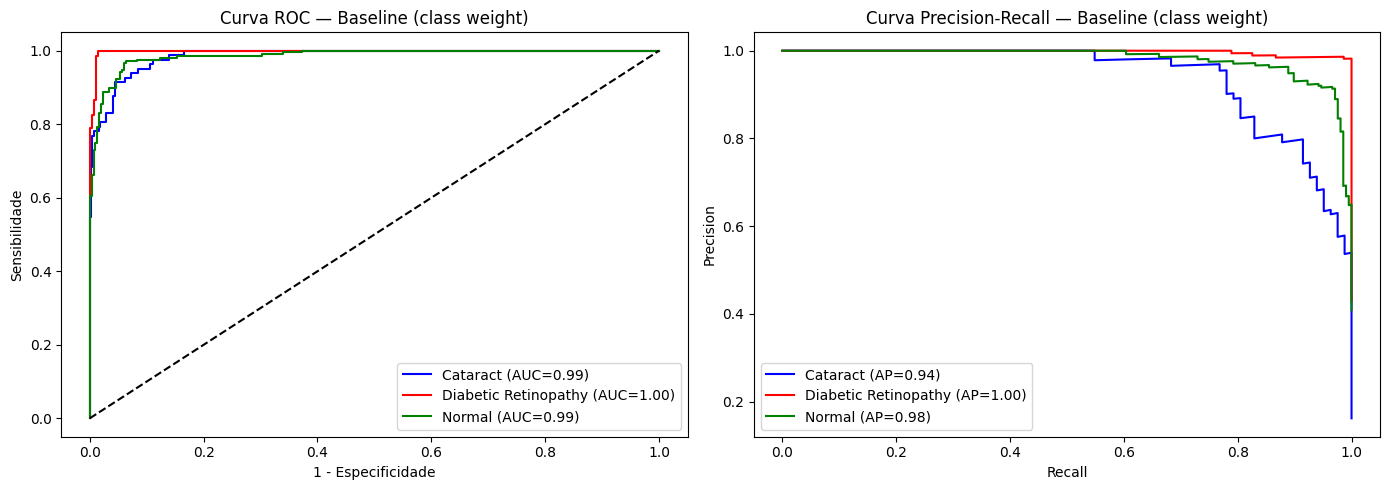


ROC e Precision-Recall -- Regularizado


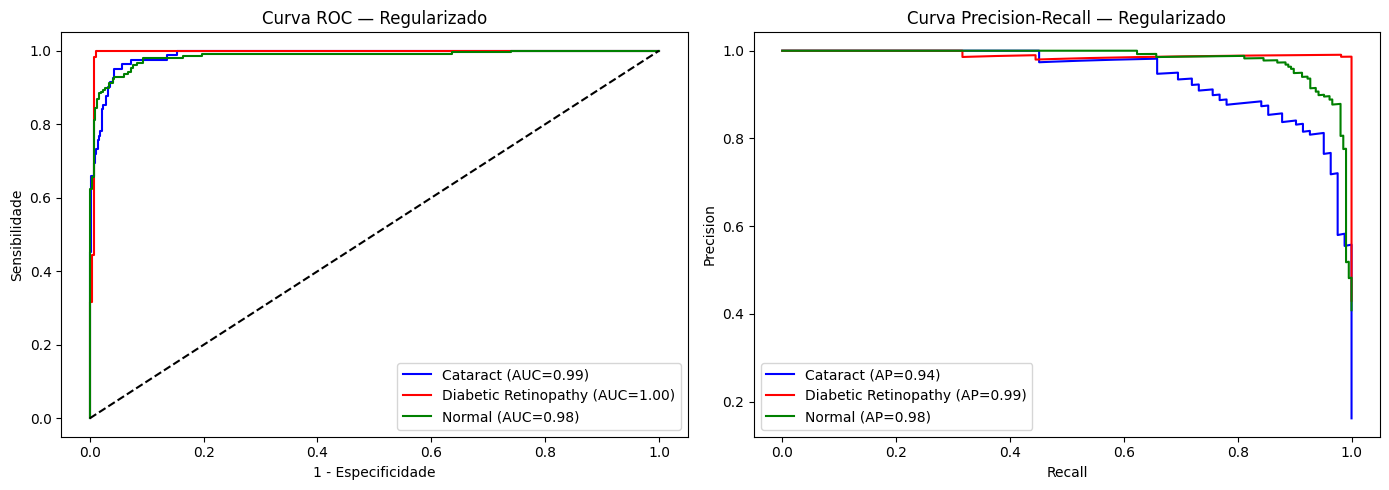


ROC e Precision-Recall -- ResNet50 (feature extraction)


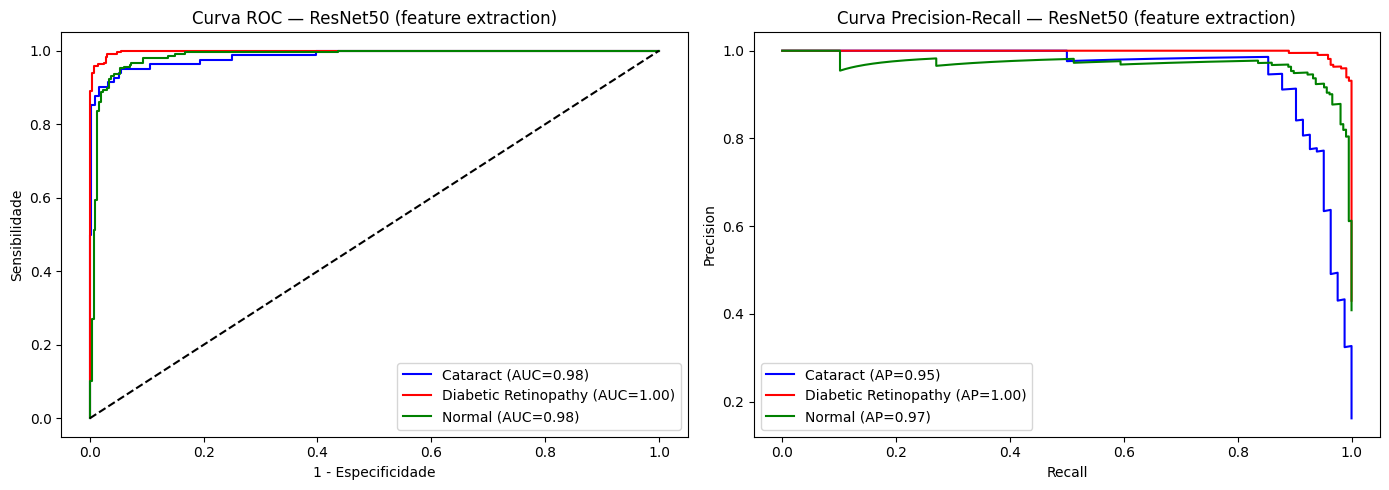


ROC e Precision-Recall -- ResNet50 (fine-tuned)


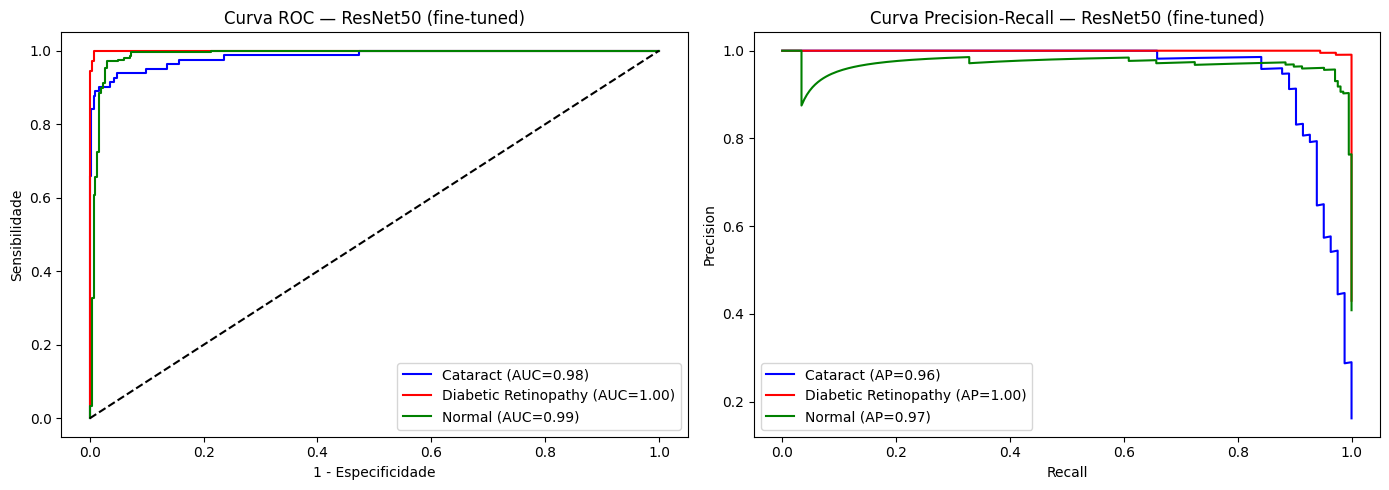


ROC e Precision-Recall -- Multimodal (ResNet50 + BERTimbau)


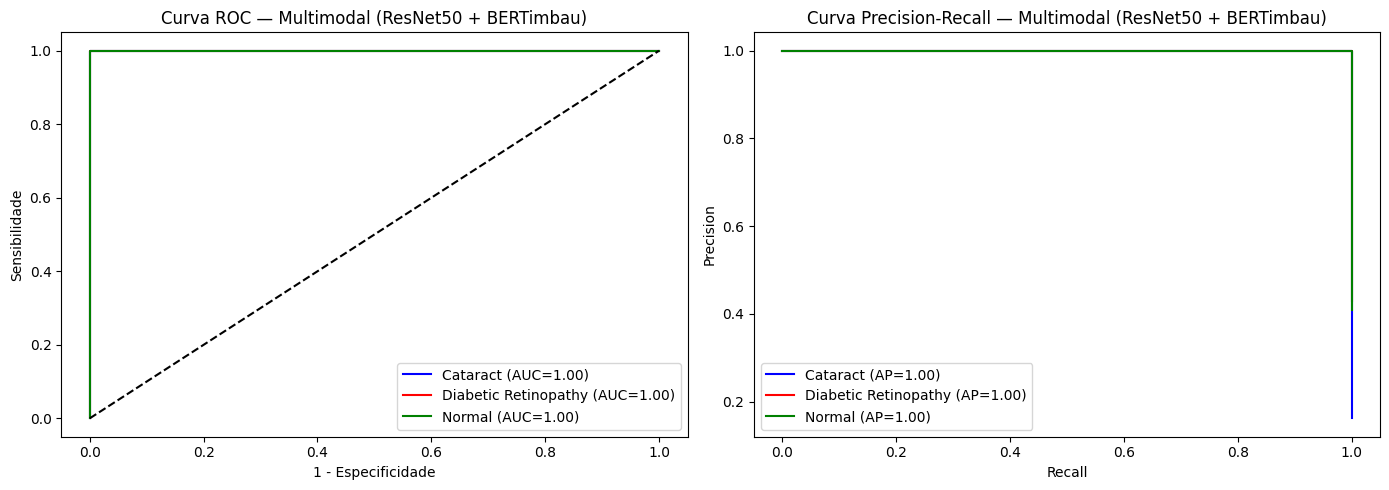


ROC e Precision-Recall -- EfficientNetB0 (feature extraction)


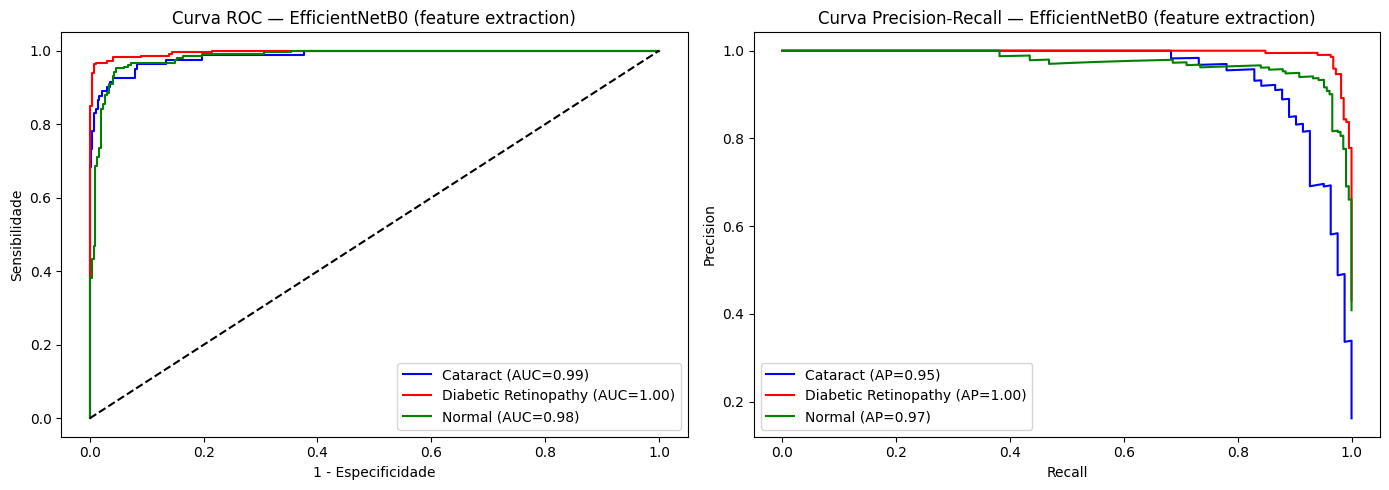


ROC e Precision-Recall -- EfficientNetB0 (fine-tuned)


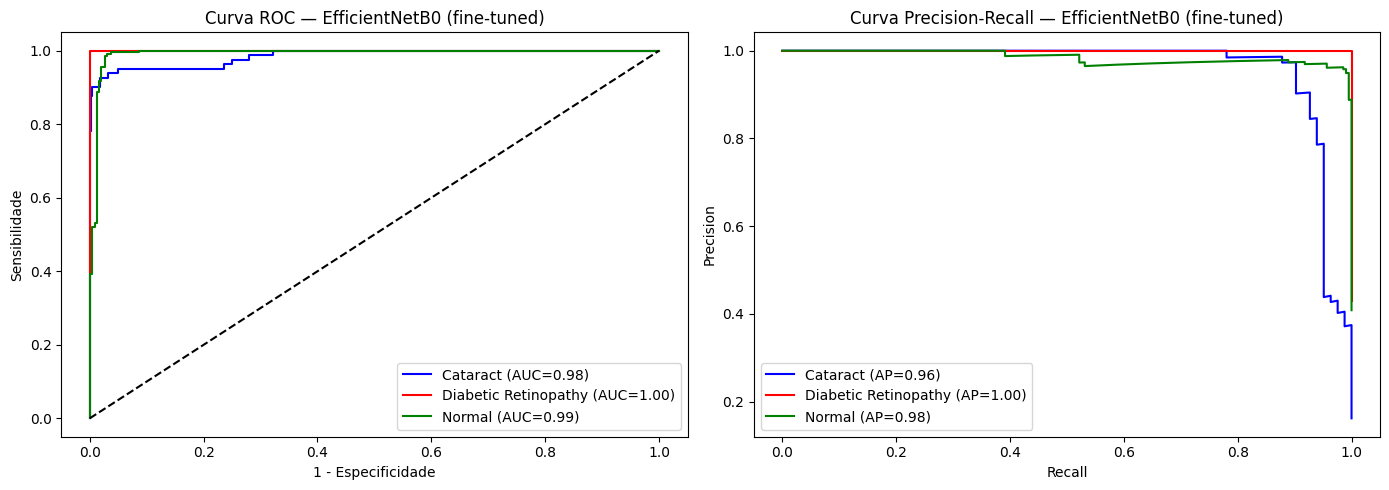


ROC e Precision-Recall -- Text-only (TF-IDF + Regressão Logística)


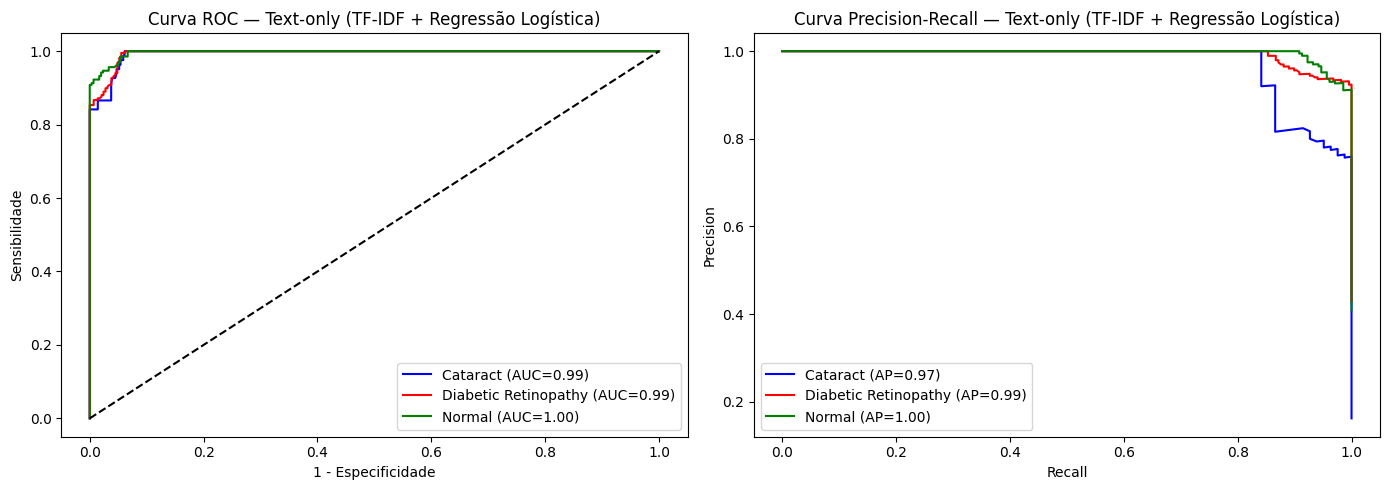

In [6]:
for nome, proba in probas.items():
    print("\n" + "="*55)
    print(f"ROC e Precision-Recall -- {nome}")
    viz.plot_roc_pr_curves(proba, y_test, class_names, nome)


## 4.5 Sensibilidade vs Especificidade por Threshold

A curva de Sensibilidade vs Especificidade por threshold permite analisar o impacto
da escolha do threshold de decisão no desempenho do modelo para cada classe.

- **Sensibilidade (Recall)** — proporção de casos positivos corretamente identificados.
  No UC3, uma sensibilidade elevada nas classes patológicas garante que doentes com
  catarata ou retinopatia diabética não são incorretamente classificados como normais.
- **Especificidade** — proporção de casos negativos corretamente identificados.
  Uma especificidade elevada reduz o número de exames normais enviados desnecessariamente
  para avaliação especializada.

O threshold padrão de 0.5 nem sempre é o mais adequado num contexto clínico. A análise
desta curva permite identificar o ponto de equilíbrio entre sensibilidade e especificidade
para cada classe, informando uma possível calibração do sistema para o contexto hospitalar.


Sensibilidade vs Especificidade -- Baseline (sem class weight)


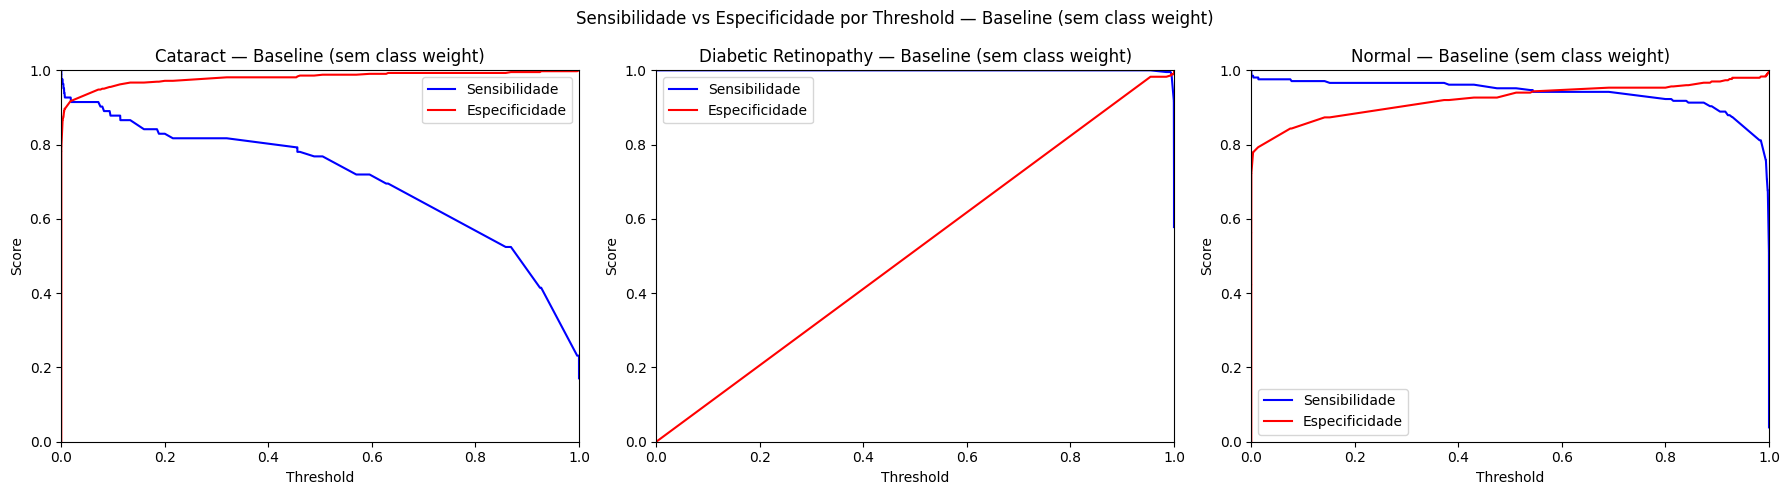


Sensibilidade vs Especificidade -- Baseline (class weight)


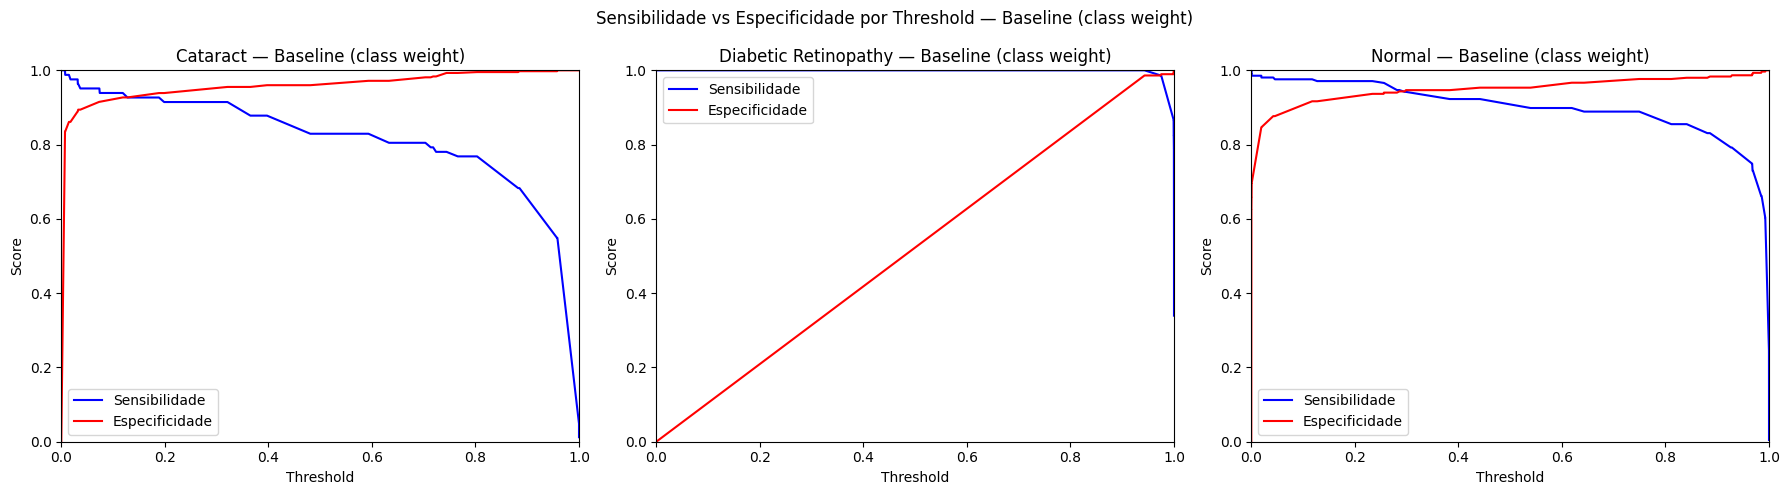


Sensibilidade vs Especificidade -- Regularizado


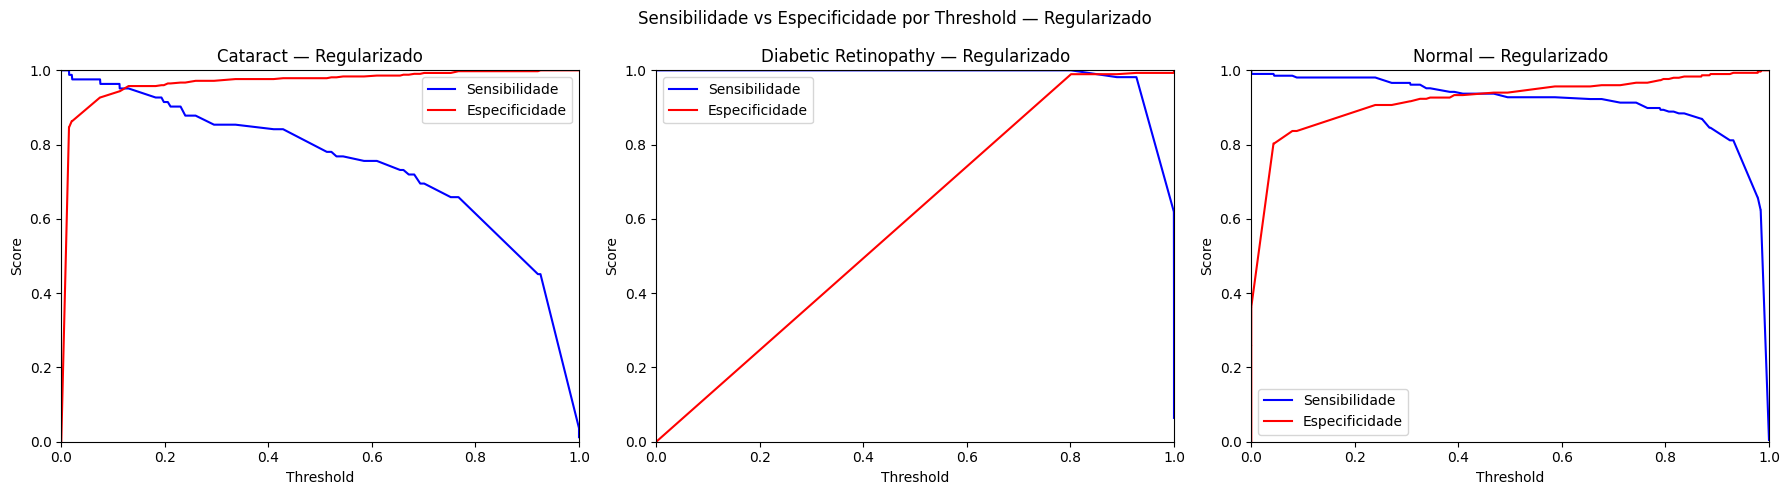


Sensibilidade vs Especificidade -- ResNet50 (feature extraction)


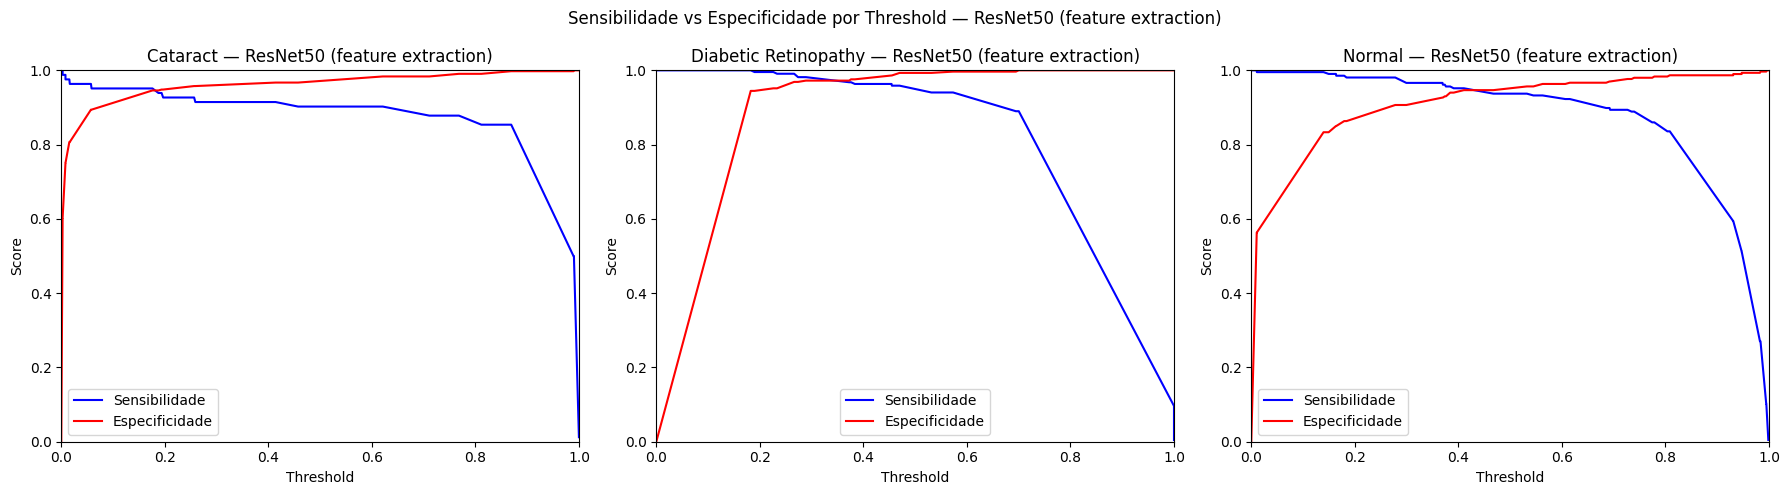


Sensibilidade vs Especificidade -- ResNet50 (fine-tuned)


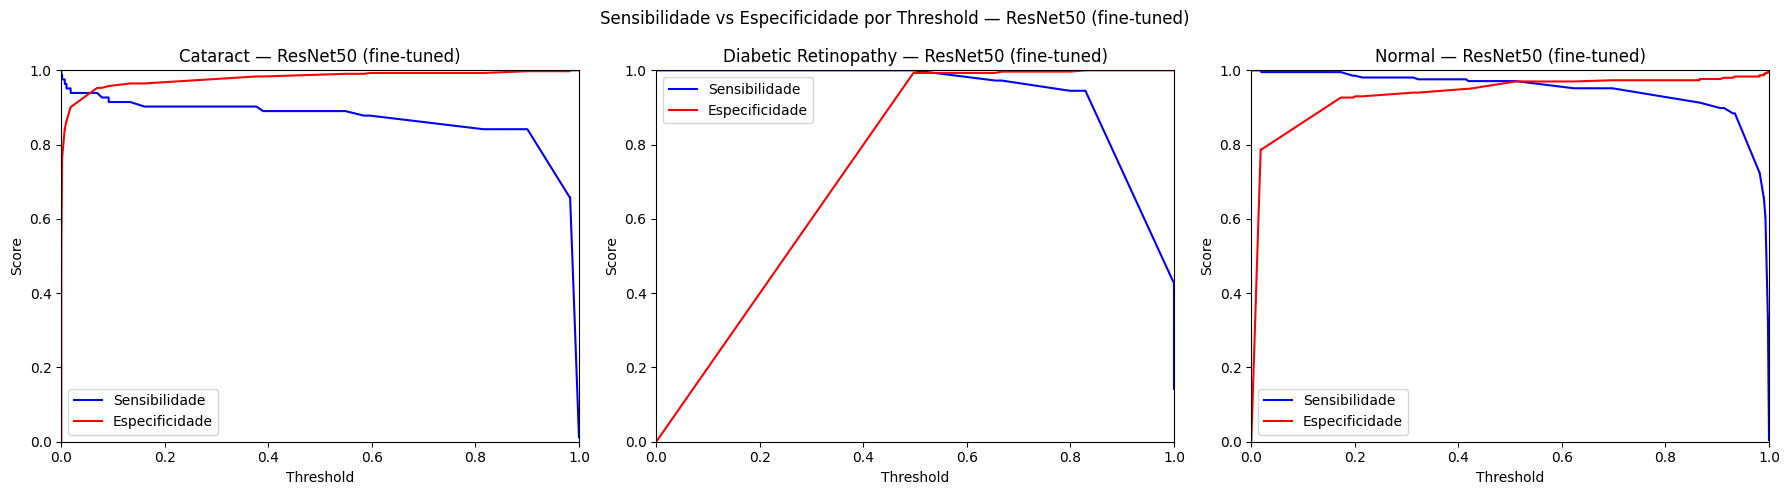


Sensibilidade vs Especificidade -- Multimodal (ResNet50 + BERTimbau)


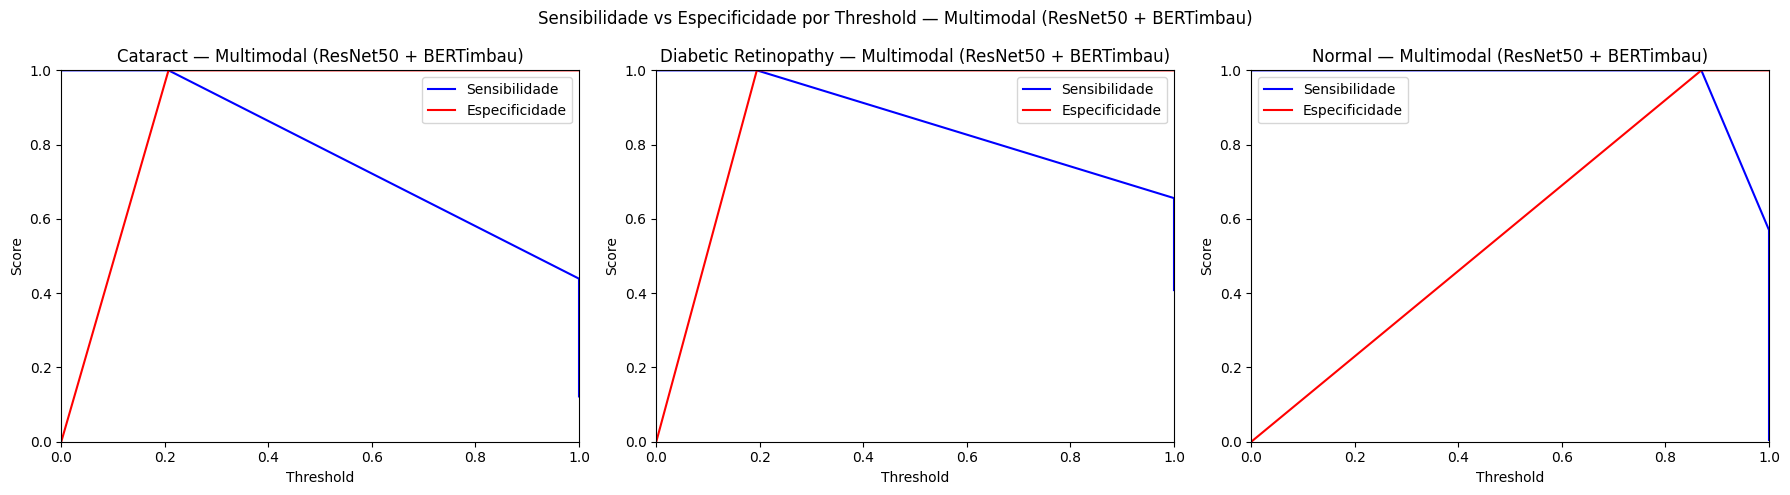


Sensibilidade vs Especificidade -- EfficientNetB0 (feature extraction)


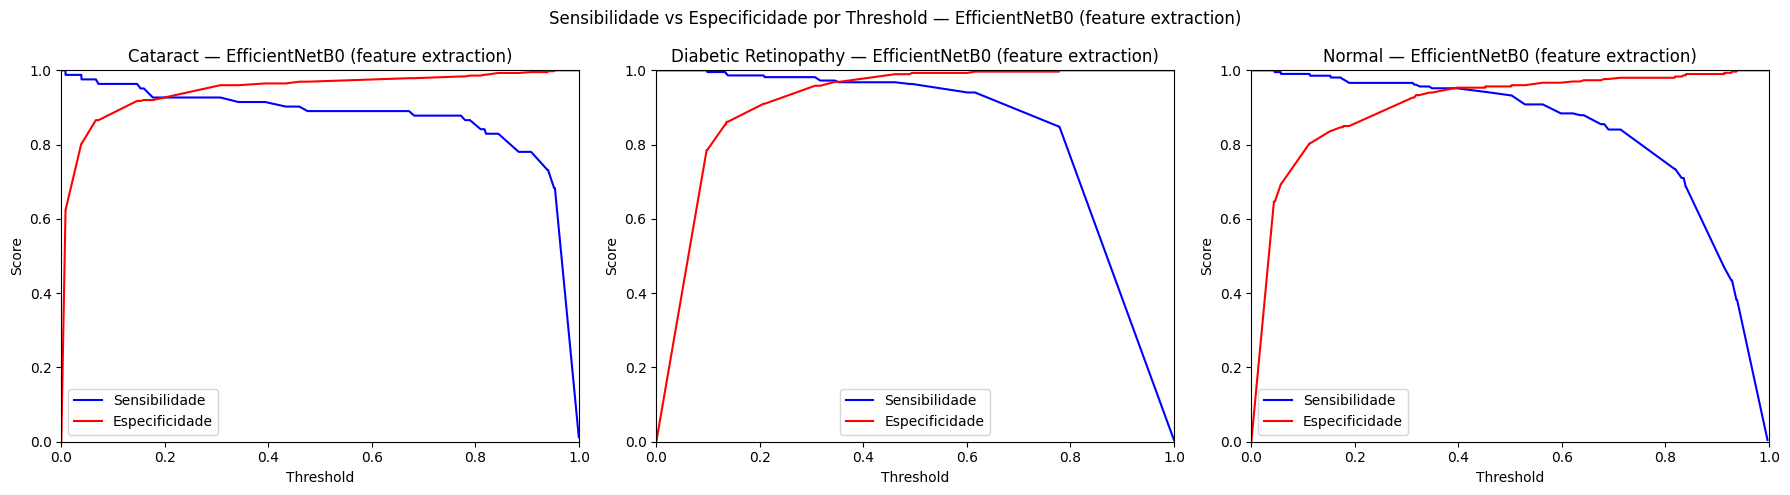


Sensibilidade vs Especificidade -- EfficientNetB0 (fine-tuned)


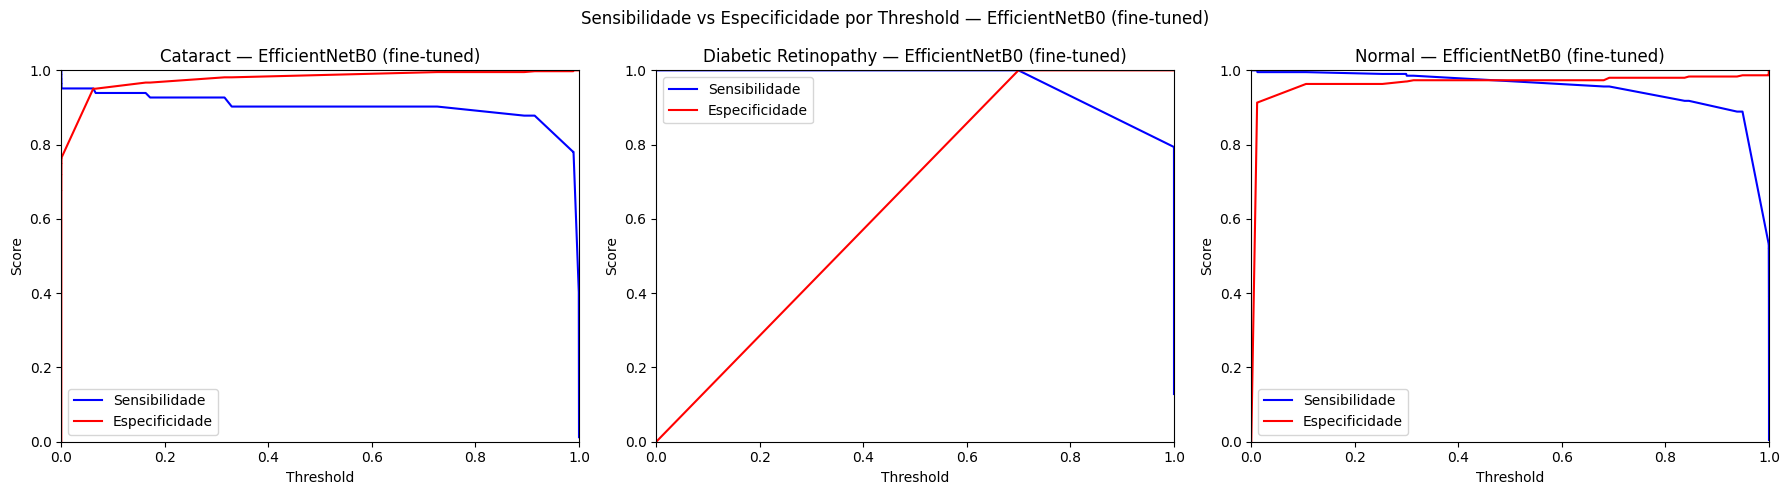


Sensibilidade vs Especificidade -- Text-only (TF-IDF + Regressão Logística)


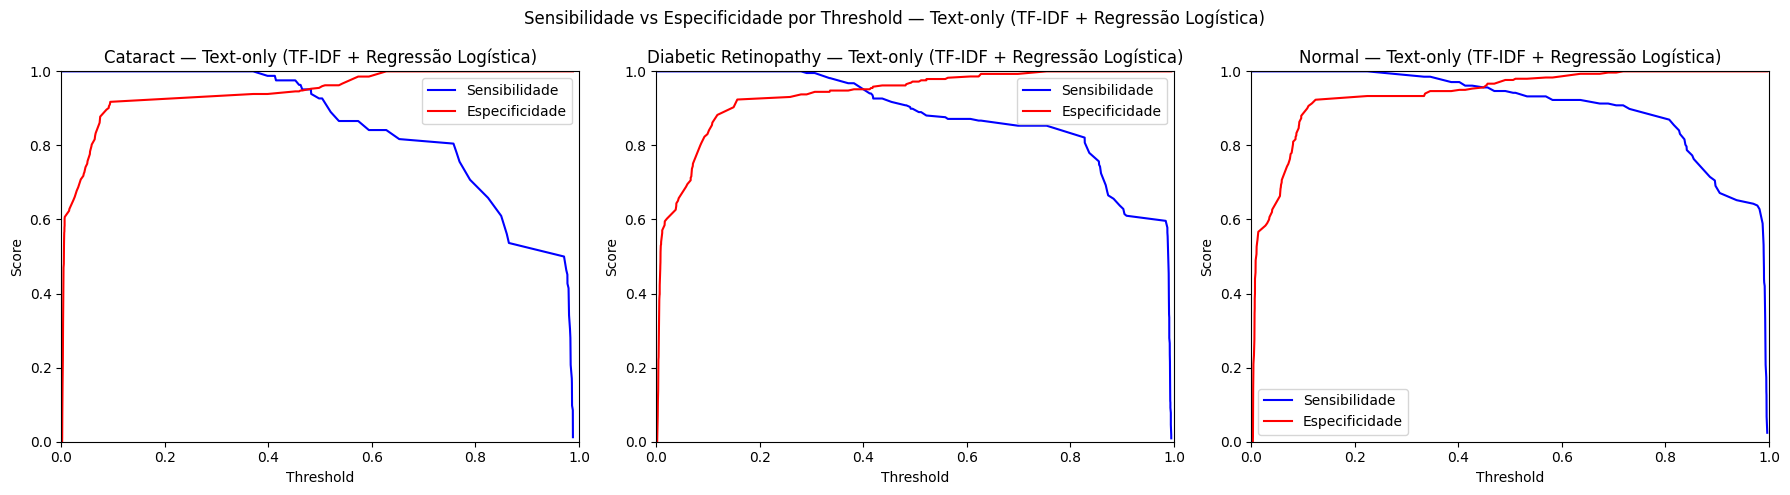

In [7]:
for nome, proba in probas.items():
    print("\n" + "="*55)
    print(f"Sensibilidade vs Especificidade -- {nome}")
    viz.plot_sensitivity_specificity_threshold(proba, y_test, class_names, nome)


## 4.6 Tabela Comparativa de Modelos

In [8]:
# Tabela comparativa
df_results.set_index("Modelo")


,Accuracy,F1-macro,AUC-ROC macro,Recall Cataract,Recall Diabetic Retinopathy,Recall Normal
Modelo,,,,,,
Baseline (sem class weight),0.942801,0.918916,0.986220,0.768293,1.000000,0.951691
Baseline (class weight),0.932939,0.908951,0.989812,0.829268,1.000000,0.903382
Regularizado,0.936884,0.914279,0.989223,0.792683,1.000000,0.927536
ResNet50 (feature extraction),0.938856,0.925075,0.988980,0.902439,0.954128,0.937198
ResNet50 (fine-tuned),0.968442,0.957699,0.990674,0.890244,0.995413,0.971014
Multimodal (ResNet50 + BERTimbau),0.992110,0.989833,1.000000,0.963415,0.995413,1.000000
EfficientNetB0 (feature extraction),0.940828,0.926155,0.988152,0.890244,0.963303,0.937198
EfficientNetB0 (fine-tuned),0.976331,0.965431,0.992289,0.902439,1.000000,0.980676
Text-only (TF-IDF + Regressão Logística),0.928994,0.916948,0.994883,0.939024,0.908257,0.946860



O modelo multimodal atinge 99.2% e AUC 1.0, mas o ganho sobre o melhor modelo de imagem (EfficientNet FT, 97.6%) não está distribuído — concentra-se na recall de catarata (0.90→0.96), a classe de sinal mais difuso e onde os modelos de imagem sistematicamente sentem dificuldades.

O  estudo do modelo baseline text-only revela porquê: apesar de globalmente inferior aos modelos de imagem (92.9%), atinge a mais alta recall de catarata de todos os modelos unimodais (0.94), porque os relatórios sintéticos codificam o diagnóstico. O multimodal não está a aprender uma fusão clínica genuína — está a usar o texto como proxy do rótulo para compensar a debilidade da imagem na catarata. Num fluxo de triagem real, onde o relatório é redigido após a avaliação, esta componente não existiria no momento da decisão, pelo que o desempenho aparente do multimodal é não-realizável.

## Justificacao do threshold de decisao

*Placeholder de um batch posterior -- sem conteudo nesta fase.*


## Reagrupamento binario: patologico vs normal

*Placeholder de um batch posterior -- sem conteudo nesta fase.* (Colapsar
Cataract + Diabetic Retinopathy numa classe "patologico" e reavaliar no teste.)


In [27]:
from sklearn.metrics import precision_recall_curve

# Predições guardadas do melhor modelo de imagem
proba = np.load(PREDS_DIR / "efficientnetb0_fine_tuned_proba.npy")

# Assumindo a ordem de classes: 0=catarata, 1=retinopatia, 2=normal.
# CONFIRMA esta ordem — se estiver trocada, tudo abaixo inverte.
idx_normal = 2

# Probabilidade de "referenciar" (= patológico = não-normal)
p_referir = 1 - proba[:, idx_normal]

# Rótulo binário: 1 = deve ser referenciado (patológico), 0 = normal
y_bin = (y_test != idx_normal).astype(int)

# Curva precision-recall da decisão de referenciação
precision, recall, thresholds = precision_recall_curve(y_bin, p_referir)


In [28]:
# Objetivo Use Case 3: maximizar precision (não referenciar normais à toa)
# SUJEITO A um mínimo de recall (não falhar patológicos).
# O mínimo de recall é a decisão clínica — aqui exemplo com 0.95.
recall_minimo = 0.95

# Entre os thresholds que garantem recall >= mínimo, escolhe o de maior precision
validos = recall[:-1] >= recall_minimo
if validos.any():
    i = np.argmax(precision[:-1][validos])
    idx = np.where(validos)[0][i]
    threshold_escolhido = thresholds[idx]
    print(f"Threshold: {threshold_escolhido:.3f}")
    print(f"Precision: {precision[idx]:.3f}  Recall: {recall[idx]:.3f}")
else:
    raise ValueError(
        f"Nenhum threshold atinge recall >= {recall_minimo}. "
        f"Recall máximo disponível: {recall[:-1].max():.3f}. "
        "Baixa o recall_minimo."
    )

Threshold: 0.914
Precision: 0.997  Recall: 0.963


In [38]:

# Predições binárias no threshold escolhido
y_pred_bin = (p_referir >= threshold_escolhido).astype(int)

# Componentes da matriz de confusão binária
VP = ((y_pred_bin == 1) & (y_bin == 1)).sum()   # patológicos apanhados
VN = ((y_pred_bin == 0) & (y_bin == 0)).sum()   # normais corretamente não referenciados
FP = ((y_pred_bin == 1) & (y_bin == 0)).sum()   # normais referenciados à toa
FN = ((y_pred_bin == 0) & (y_bin == 1)).sum()   # patológicos falhados

# Coordenadas do ponto na ROC
tpr_op = VP / (VP + FN)          # sensibilidade / recall
fpr_op = FP / (FP + VN)          # 1 - especificidade

total = len(y_test)
referenciados = VP + FP
nao_referenciados = VN + FN

print(f"Total de exames no teste: {total}")
print(f"─" * 40)
print(f"Referenciados: {referenciados}")
print(f"  patológicos corretos (VP): {VP}")
print(f"  normais incorretamente referenciados (FP): {FP}")
print(f"Não referenciados: {nao_referenciados}")
print(f"  normais evitados (VN): {VN}")
print(f"  patológicos não referenciados (FN): {FN}")
print(f"─" * 40)
print(f"Verificação: {referenciados} + {nao_referenciados} = {referenciados + nao_referenciados}")

Total de exames no teste: 507
────────────────────────────────────────
Referenciados: 290
  patológicos corretos (VP): 289
  normais incorretamente referenciados (FP): 1
Não referenciados: 217
  normais evitados (VN): 206
  patológicos não referenciados (FN): 11
────────────────────────────────────────
Verificação: 290 + 217 = 507


In [36]:
# Dos falsos negativos, quais eram catarata (0) e quais retinopatia (1)?
fn_mask = (y_pred_bin == 0) & (y_bin == 1)
classes_fn = y_test[fn_mask]   # rótulos originais dos falhados

import numpy as np
for cls, nome in [(0, "catarata"), (1, "retinopatia")]:
    print(f"{nome}: {(classes_fn == cls).sum()}")

catarata: 10
retinopatia: 1


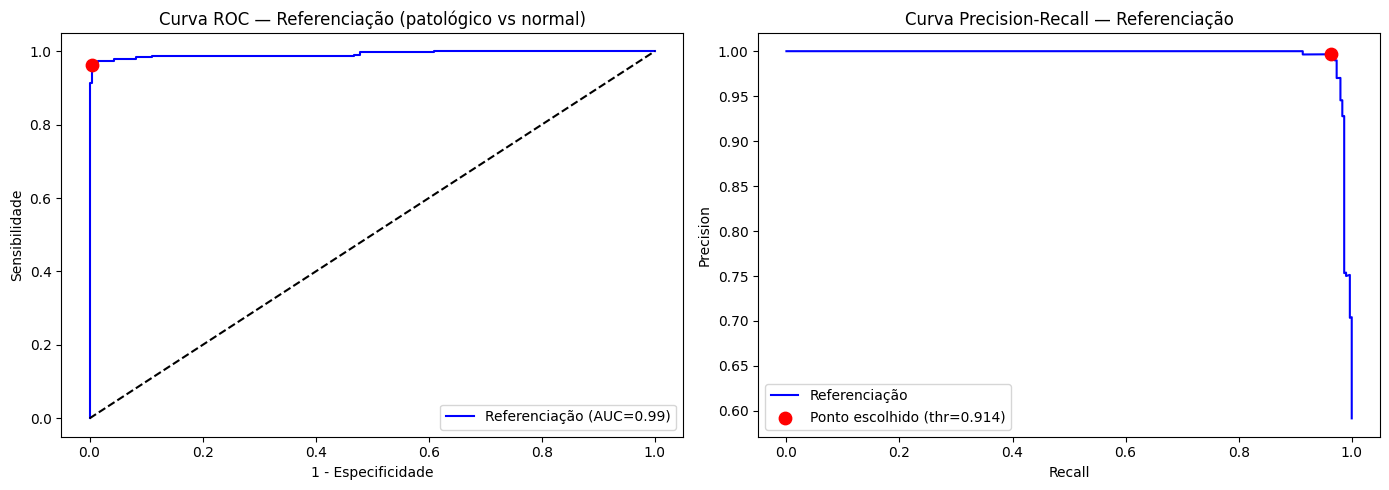

In [31]:
from sklearn.metrics import roc_curve, auc

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC binária
fpr, tpr, _ = roc_curve(y_bin, p_referir)
roc_auc = auc(fpr, tpr)
axes[0].plot(fpr, tpr, color="blue", label=f"Referenciação (AUC={roc_auc:.2f})")
axes[0].plot([0, 1], [0, 1], "k--")
# marcar o ponto de operação na ROC

axes[0].scatter([fpr_op], [recall[idx]], color="red", s=80, zorder=5)
axes[0].set_title("Curva ROC — Referenciação (patológico vs normal)")
axes[0].set_xlabel("1 - Especificidade"); axes[0].set_ylabel("Sensibilidade")
axes[0].legend()

# PR binária
axes[1].plot(recall, precision, color="blue", label="Referenciação")
axes[1].scatter([recall[idx]], [precision[idx]], color="red", s=80, zorder=5,
                label=f"Ponto escolhido (thr={threshold_escolhido:.3f})")
axes[1].set_title("Curva Precision-Recall — Referenciação")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

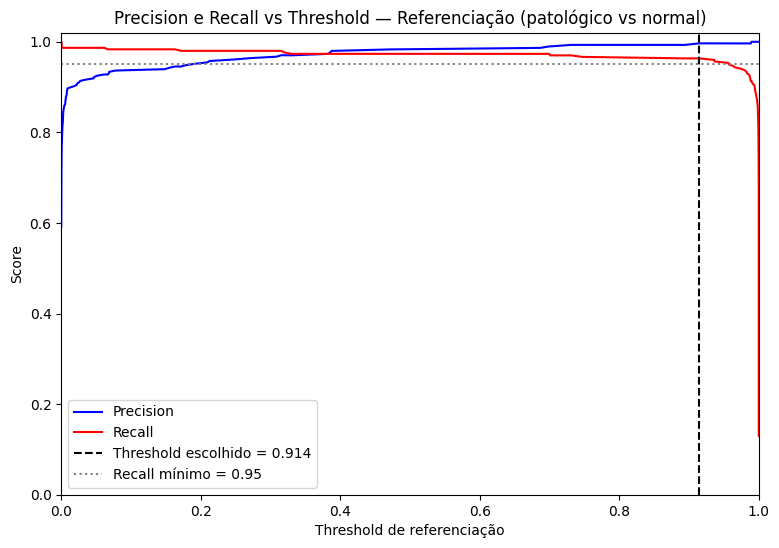

In [32]:
# precision, recall, thresholds já vêm do precision_recall_curve
# (recall e precision têm 1 elemento a mais que thresholds)
plt.figure(figsize=(9, 6))
plt.plot(thresholds, precision[:-1], color="blue", label="Precision")
plt.plot(thresholds, recall[:-1], color="red", label="Recall")

# linha vertical no threshold escolhido
plt.axvline(threshold_escolhido, color="black", linestyle="--",
            label=f"Threshold escolhido = {threshold_escolhido:.3f}")

# linha horizontal no recall mínimo que exigiste
plt.axhline(recall_minimo, color="gray", linestyle=":",
            label=f"Recall mínimo = {recall_minimo}")

plt.xlabel("Threshold de referenciação")
plt.ylabel("Score")
plt.title("Precision e Recall vs Threshold — Referenciação (patológico vs normal)")
plt.legend()
plt.xlim([0, 1])
plt.ylim([0, 1.02])
plt.show()